# 05 · Does deep learning fix it?

The published approach to this problem is **image-based**. Boulila et al.
(2023) convert each recording into cepstral-coefficient images, stack them,
and classify with ImageNet CNNs — reporting **100%** accuracy, including on
TreeVibes. Karar et al. (2022) do the same with MixConvNet: **97.4%**.

This project classifies hand-designed features instead, which invites the
obvious question a judge will ask:

> *"Did you just not try deep learning?"*

So we try it — under the same two protocols used everywhere else here. The
purpose is not to win a benchmark. It is to test whether **model capacity has
anything to do with the problem**.

If the CNN reproduces near-perfect accuracy on a random split and collapses
on a grouped split, then the published results measure **the protocol**, not
the method — and no architecture will fix that.

### A note on model size

The CNN here is deliberately small (~24k parameters, three conv blocks). That
is the honest choice, not a handicap. The number of *independent* samples in
this data is the number of **trees** (roughly 10–35), not the number of clips.
Fine-tuning a 25-million-parameter ImageNet backbone on 35 independent units
fits the trees perfectly and tells you nothing — which is exactly the failure
being documented. A small model keeps the comparison about the protocol.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent          # the nakheel-guard folder
for sub in ("src", "scripts"):
    sys.path.insert(0, str(ROOT / sub))

# These imports are wrapped because the most common way they fail on Anaconda
# produces an error that never mentions the real cause. Installing an audio
# library with pip can upgrade NumPy past 2.0, and Anaconda's pre-compiled
# matplotlib / scipy / pandas were built against NumPy 1.x -- so the failure
# surfaces as "initialization failed" deep inside matplotlib's import chain,
# with no hint that NumPy is responsible.
try:
    import numpy as np, pandas as pd, matplotlib.pyplot as plt
except ImportError as _exc:
    _numpy_version = "unknown"
    try:
        import numpy as _np_probe
        _numpy_version = _np_probe.__version__
    except Exception:
        pass
    raise ImportError(f"""Core imports failed. NumPy version: {_numpy_version}

This is almost always a mixed environment: some packages were built for
NumPy 1.x and others require NumPy 2.x, so no single NumPy version satisfies
everything. Typical symptoms are "module compiled using NumPy 1.x cannot be
run in NumPy 2" or "module 'numpy' has no attribute 'long'".

Pinning NumPy does NOT fix this -- in a genuinely mixed environment each pin
only moves the failure to a different package. Build a clean environment:

    conda create -n nakheel python=3.11 -y
    conda activate nakheel
    pip install -r requirements.txt
    pip install jupyterlab ipykernel
    python -m ipykernel install --user --name nakheel --display-name "Python (nakheel)"

then start Jupyter from that prompt and choose
Kernel -> Change Kernel -> Python (nakheel).

If a package is merely missing rather than mismatched, install it into THIS
kernel with:

    import sys
    !"{sys.executable}" -m pip install --upgrade-strategy only-if-needed <package>

Original error: {_exc}
""") from _exc

get_ipython().run_line_magic("matplotlib", "inline")
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)

In [2]:
# ---------------------------------------------------------------- packages
# Check the packages this project needs are importable *in the Python that is
# running this notebook*. On Anaconda, `pip` on the command line often points
# at a different environment than Jupyter uses, which is a common and
# confusing source of "but I installed it" failures.
_missing = []
for _mod, _pkg in [("numpy", "numpy"), ("pandas", "pandas"),
                   ("sklearn", "scikit-learn"), ("scipy", "scipy"),
                   ("librosa", "librosa"), ("soundfile", "soundfile"),
                   ("joblib", "joblib"), ("matplotlib", "matplotlib"),
                   ("openpyxl", "openpyxl")]:
    try:
        __import__(_mod)
    except ImportError:
        _missing.append(_pkg)

if _missing:
    raise ImportError(f"""Missing packages: {', '.join(_missing)}

Install them into THIS kernel by running the following in a new cell,
then restart the kernel (Kernel -> Restart):

    import sys
    !"{sys.executable}" -m pip install --upgrade-strategy only-if-needed {' '.join(_missing)}

The --upgrade-strategy flag matters: without it pip may upgrade NumPy to
satisfy the new package, which can break other packages compiled against a
different NumPy generation. If that happens, see the README -- the fix is a
clean environment, not a NumPy pin.
""")

print("packages: OK")

# ---------------------------------------------------------------- dataset
# "mock"      - structurally faithful stand-in, synthetic audio. For testing.
# "treevibes" - the real download. Put it in data/treevibes/.
WHICH = "treevibes"

DATASETS = {
    "mock":      ROOT / "data" / "mock_treevibes",
    "treevibes": ROOT / "data" / "treevibes",
}
DATASET = DATASETS[WHICH]
TAG = "mock" if WHICH == "mock" else "treevibes"

# The Kaggle distribution splits into field/ and lab/. Only the field
# recordings describe deployed sensors on real trees -- the lab set is
# controlled-condition material that would both swamp the field data (roughly
# 53,000 clips against 4,000) and mix two very different acoustic regimes
# under one label. The published analyses use the field recordings, so that
# is what this project evaluates on.
if WHICH == "treevibes" and (DATASET / "field").is_dir():
    DATASET = DATASET / "field"
    print("using the field recordings only (lab/ excluded)")

if not DATASET.exists():
    if WHICH == "mock":
        # Imported and called directly rather than run as a subprocess, so a
        # failure arrives as an ordinary traceback naming its cause instead
        # of an opaque "non-zero exit status 1".
        import make_mock_treevibes
        print("building the mock dataset (a few minutes)...")
        make_mock_treevibes.generate(out=DATASET, folders=10, days=110,
                                     per_day=2, seconds=3.0)
    else:
        raise FileNotFoundError(f"""{DATASET} not found.

Download TreeVibes from
    https://www.kaggle.com/datasets/potamitis/treevibes
and extract it into
    {DATASET}
""")
print(f"dataset: {DATASET}  (tag '{TAG}')")

packages: OK
using the field recordings only (lab/ excluded)
dataset: C:\Users\DELL\Downloads\nakheel-final\nakheel-final\data\treevibes\field  (tag 'treevibes')


## 1. Turn the audio into images

This is the representation the published pipelines use.

In [3]:
from spectro_cnn import build_image_set, spectrogram_image, TORCH_AVAILABLE
import treevibes as TV

if not TORCH_AVAILABLE:
    raise ImportError("This notebook needs PyTorch:  pip install torch")

IMG_CACHE = ROOT / "results" / f"images_{TAG}.npz"

if IMG_CACHE.exists():
    d = np.load(IMG_CACHE, allow_pickle=True)
    Ximg, yimg, gimg = d["X"], d["y"], d["groups"]
    print(f"loaded cache: {Ximg.shape}")
else:
    man = pd.read_csv(ROOT / "results" / f"manifest_{TAG}.csv")
    print(f"building spectrogram images from {len(man)} recordings...")
    Ximg, yimg, gimg, ids = build_image_set(
        man.path.values, man.y.values, man.group.values)
    np.savez_compressed(IMG_CACHE, X=Ximg, y=yimg, groups=gimg, clip_ids=ids)
    print(f"built {Ximg.shape}")

print(f"clean={int((yimg==0).sum())}  infested={int((yimg==1).sum())}  "
      f"trees={len(set(gimg))}")

building spectrogram images from 2400 recordings...


C:\Users\DELL\anaconda3\envs\nakheel\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\DELL\Downloads\nakheel-final\nakheel-final\src\features.py:48: UserWarning: PySoundFile failed. Trying audioread instead.
  y, _ = librosa.load(str(path), sr=sr, mono=True)
C:\Users\DELL\anaconda3\envs\nakheel\Lib\site-packages\librosa\core\audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


    300/2400 recordings


    600/2400 recordings


    900/2400 recordings


    1500/2400 recordings


    1800/2400 recordings


    2100/2400 recordings


    2400/2400 recordings


built (38675, 1, 48, 48)
clean=16192  infested=22483  trees=36


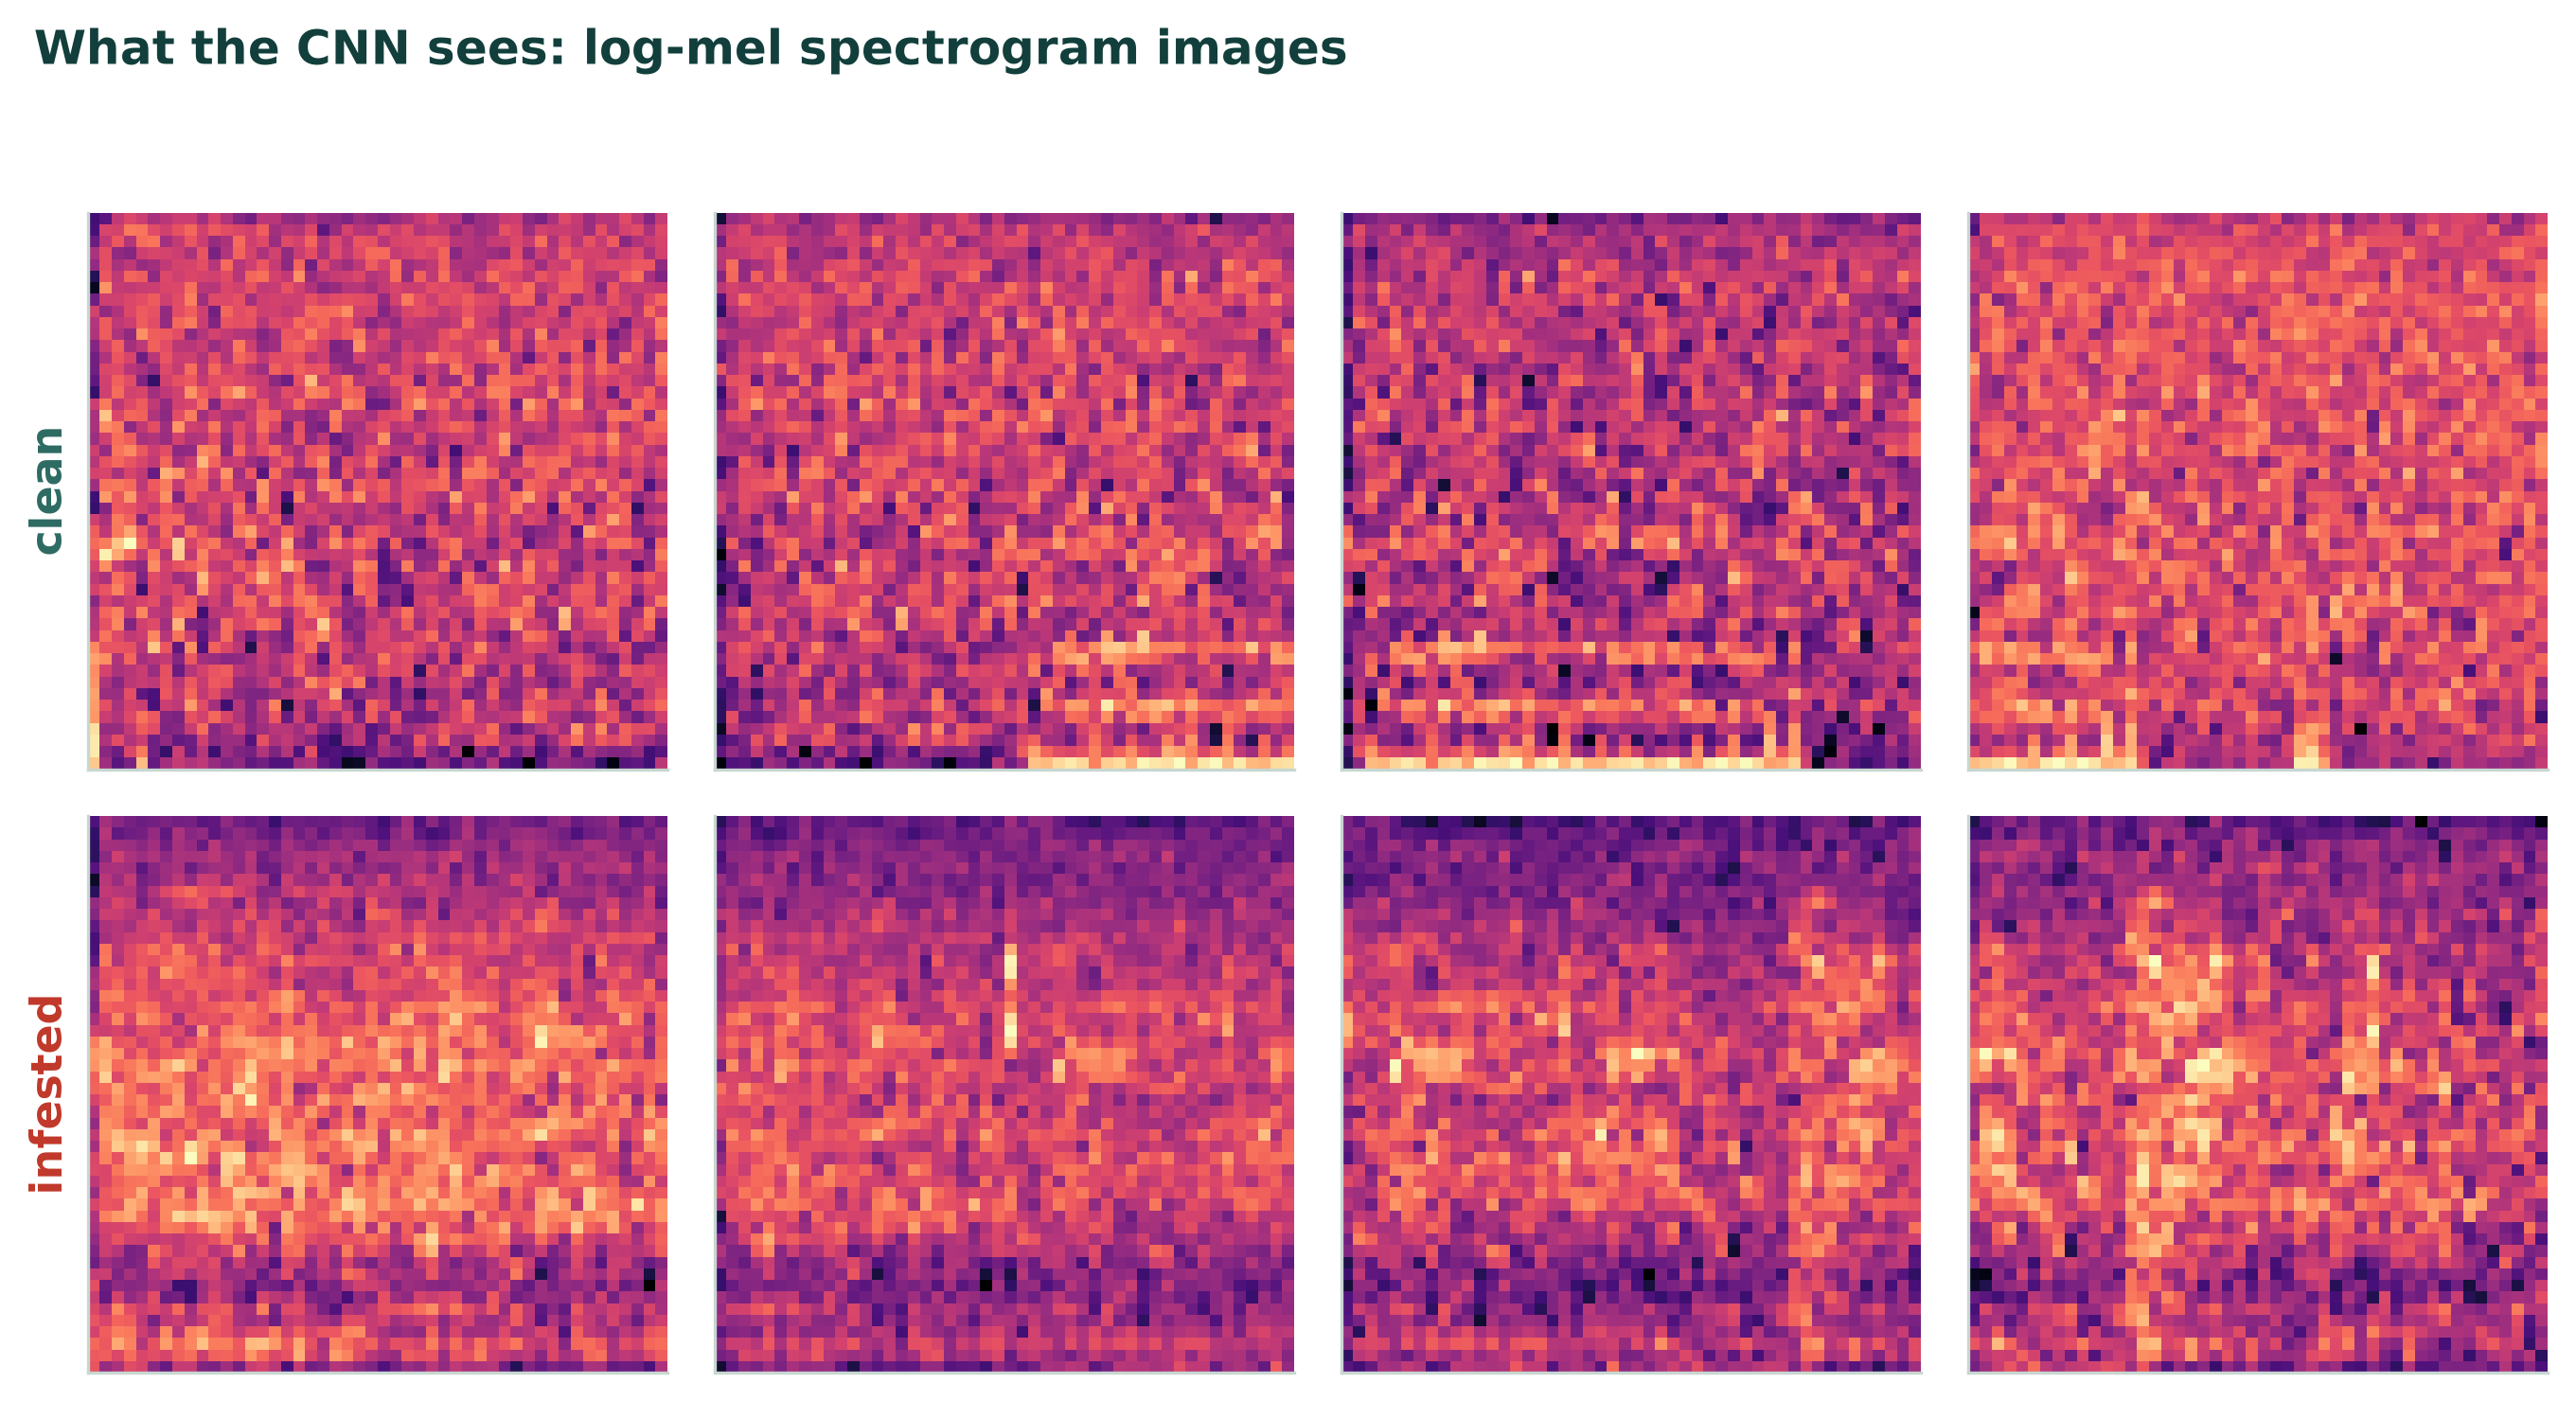

In [4]:
import plots as P
from IPython.display import Image, display
display(Image(str(P.fig_spectrogram_examples(Ximg, yimg)), width=700))

## 2. Train the CNN under both protocols

Same splitters as every other notebook, so the comparison isolates the model
and the protocol and nothing else.

On a laptop CPU this takes a while — five folds twice over. Reduce `epochs`
or `n_splits` for a quick look.

In [5]:
from spectro_cnn import evaluate
import json

EPOCHS, SPLITS = 12, 5

print("GROUPED  (test trees unseen)")
cnn_grouped = evaluate(Ximg, yimg, gimg, "grouped", n_splits=SPLITS, epochs=EPOCHS)
print()
print("RANDOM   (clips shuffled)")
cnn_random  = evaluate(Ximg, yimg, gimg, "random",  n_splits=SPLITS, epochs=EPOCHS)

(ROOT / "results" / "cnn_report.json").write_text(
    json.dumps({"grouped": cnn_grouped, "random": cnn_random},
               indent=2, default=float))

g = cnn_grouped["mean"]["balanced_accuracy"]
r = cnn_random["mean"]["balanced_accuracy"]
print()
print(f"CNN balanced accuracy:  random {r:.3f}   grouped {g:.3f}   gap {r-g:+.3f}")
print(f"CNN ROC-AUC:            random {cnn_random['mean']['roc_auc']:.3f}   "
      f"grouped {cnn_grouped['mean']['roc_auc']:.3f}")

GROUPED  (test trees unseen)


    fold 1/5 (train 30180, test 8495)


    fold 2/5 (train 30483, test 8192)


    fold 3/5 (train 31170, test 7505)


    fold 4/5 (train 31260, test 7415)


    fold 5/5 (train 31607, test 7068)


... (2 outputs left out)

    fold 3/5 (train 30940, test 7735)


    fold 4/5 (train 30940, test 7735)


    fold 5/5 (train 30940, test 7735)



CNN balanced accuracy:  random 0.917   grouped 0.483   gap +0.434
CNN ROC-AUC:            random 0.977   grouped 0.441


### Read the grouped ROC-AUC carefully

If it is **below 0.5**, the CNN is *anti-predictive* on unseen trees: its
confidence points the wrong way. That is the same inversion notebook 03 found
in the shift direction, reached independently by a completely different model
family — which is strong evidence that it is a property of the data, not of
any one method.

## 3. The comparison that answers the question

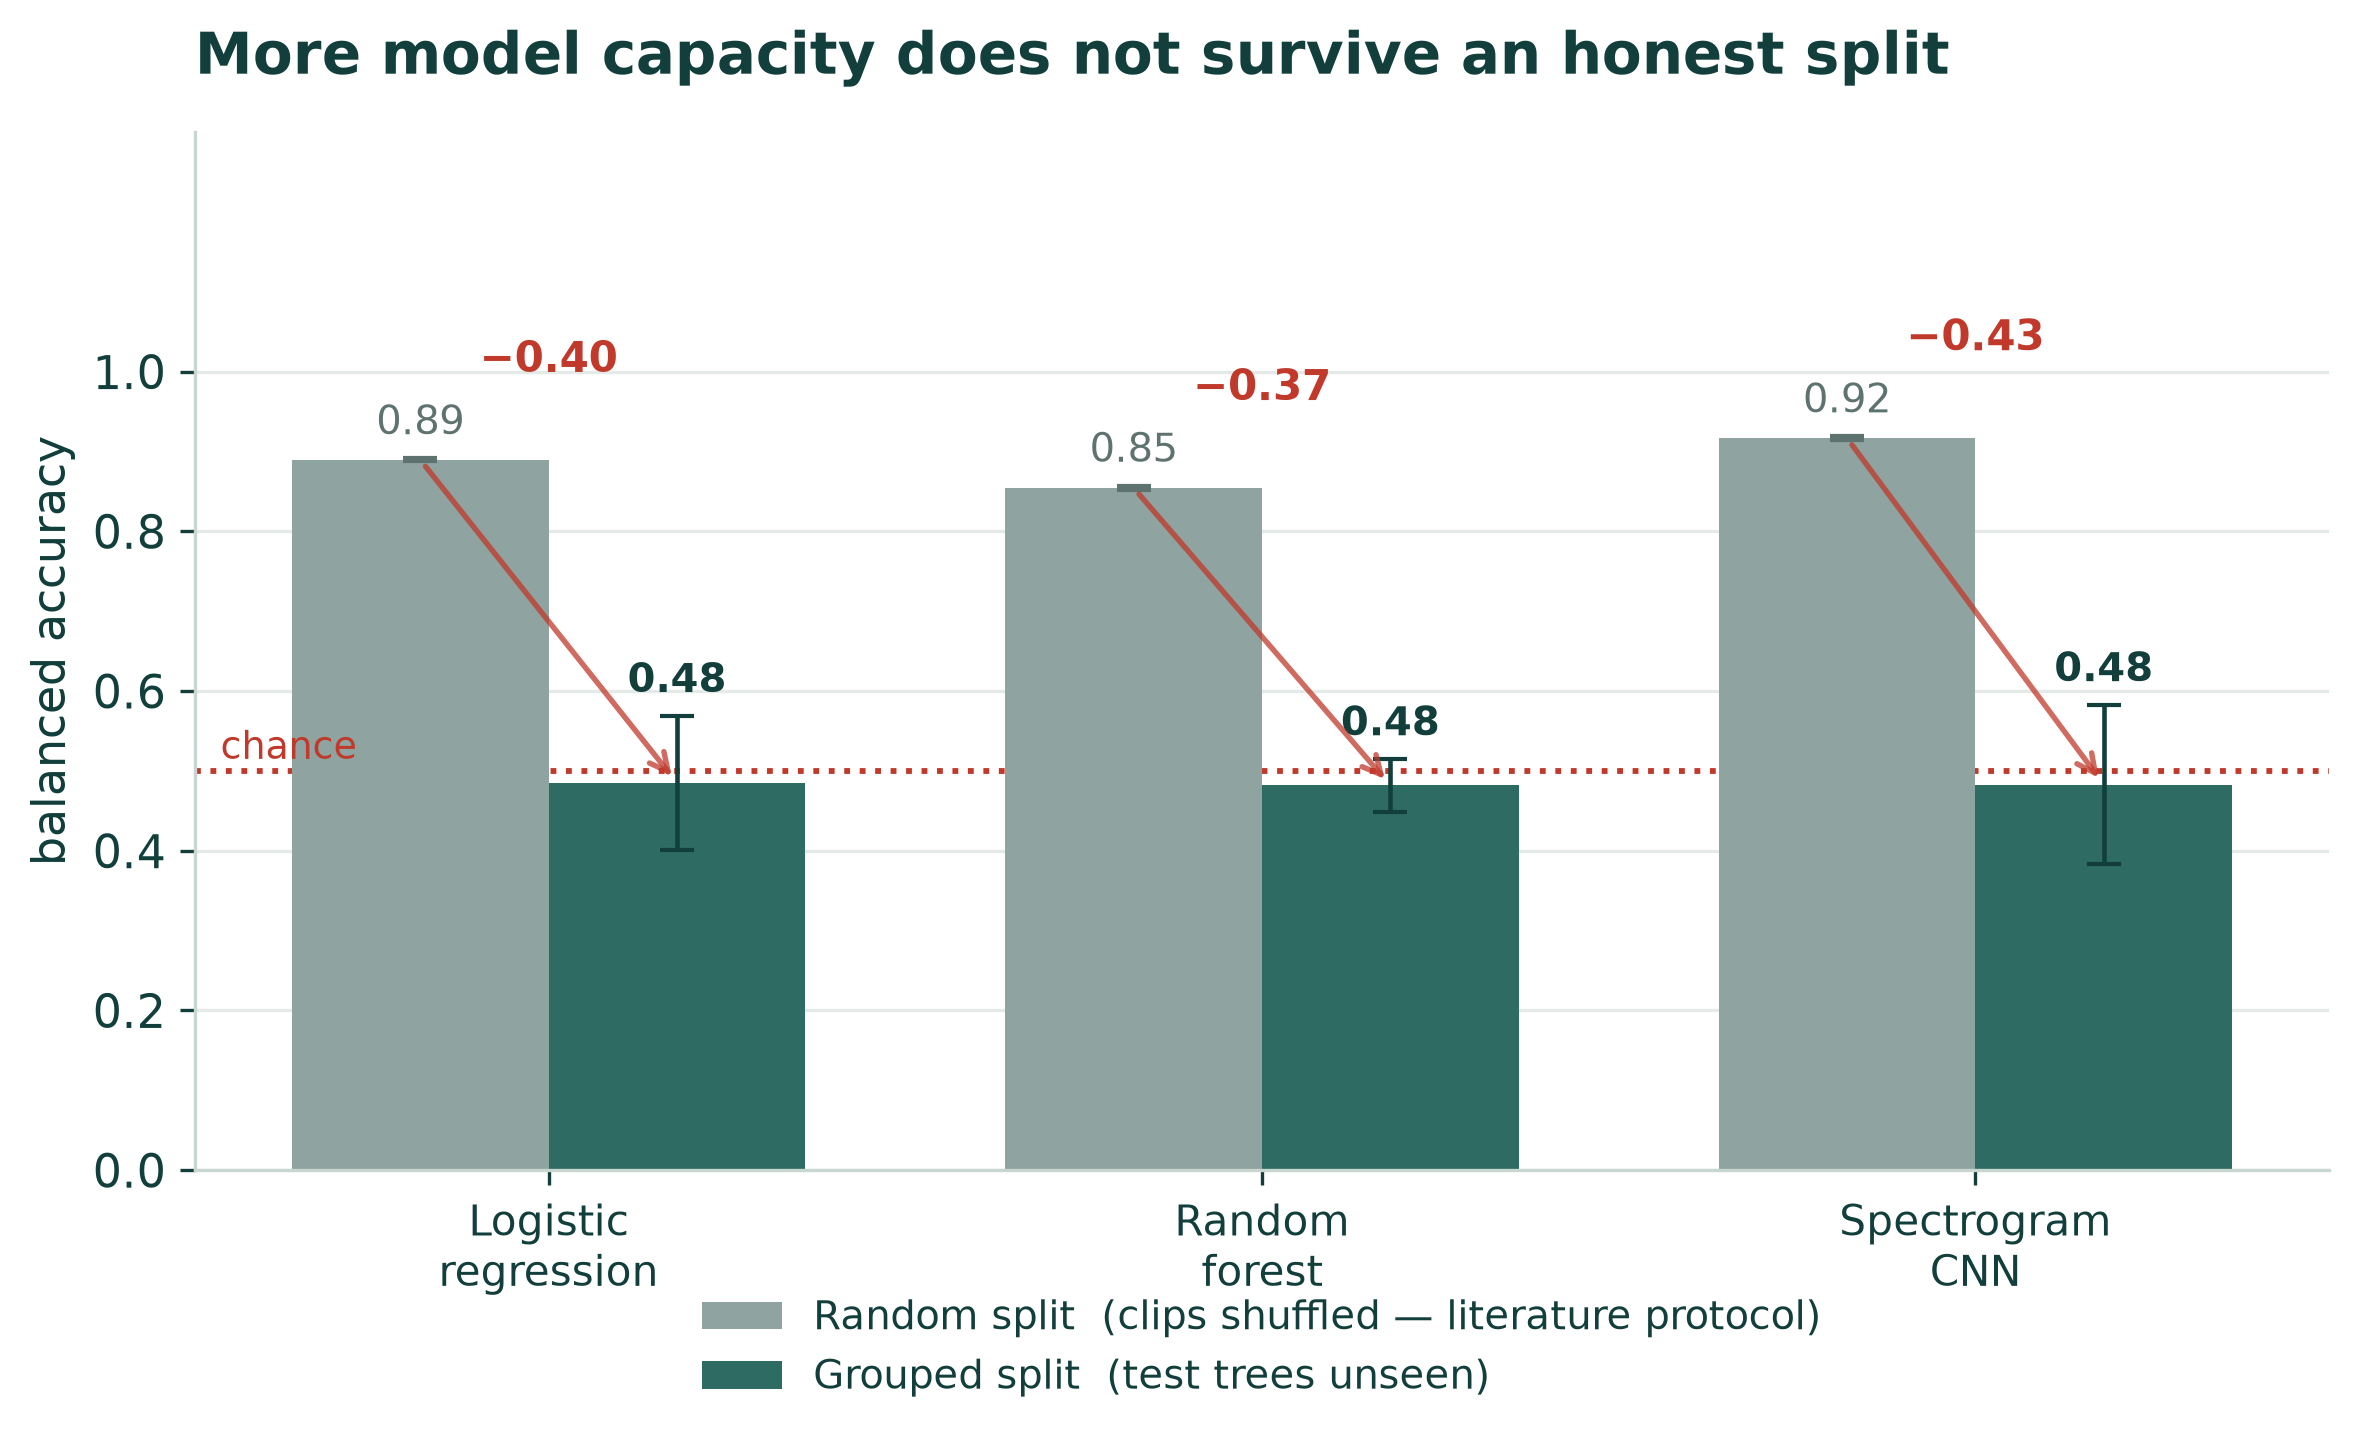

model                      random  grouped     drop
Logistic regression         0.890    0.485   +0.405
Random forest               0.854    0.482   +0.373
Spectrogram CNN             0.917    0.483   +0.434


In [6]:
feat = json.loads((ROOT / "results" / "report.json").read_text())

name_map = {"logistic_regression": "Logistic regression",
            "random_forest": "Random forest"}
rows = []
for m in ["logistic_regression", "random_forest"]:
    if m in feat["grouped"]:
        rows.append({"model": name_map[m],
                     "random":    feat["random"][m]["mean"]["balanced_accuracy"],
                     "random_sd": feat["random"][m]["std"]["balanced_accuracy"],
                     "grouped":   feat["grouped"][m]["mean"]["balanced_accuracy"],
                     "grouped_sd":feat["grouped"][m]["std"]["balanced_accuracy"]})
rows.append({"model": "Spectrogram CNN",
             "random": r, "random_sd": cnn_random["std"]["balanced_accuracy"],
             "grouped": g, "grouped_sd": cnn_grouped["std"]["balanced_accuracy"]})

(ROOT / "results" / "model_vs_protocol.json").write_text(json.dumps(rows, indent=2))
display(Image(str(P.fig_model_vs_protocol(rows)), width=880))

print(f"{'model':<24}{'random':>9}{'grouped':>9}{'drop':>9}")
for row in rows:
    nm = row["model"]
    print(f"{nm:<24}{row['random']:>9.3f}{row['grouped']:>9.3f}"
          f"{row['random']-row['grouped']:>+9.3f}")

## What this establishes

Read the drops across the three models. If they **grow** with model capacity,
the conclusion is sharp and uncomfortable for the field:

> Every model reaches roughly the same accuracy under a random split. The
> more capacity a model has, the **further it falls** when the split stops
> leaking — because more capacity means a better ability to memorise which
> tree a recording came from.

A CNN is not a solution to this problem. It is a more efficient exploiter of
it.

### How to answer the judge

> *"Did you try deep learning?"*
>
> "Yes. I implemented the published spectrogram-CNN approach and evaluated it
> the same way as everything else. Under the random split used in the
> literature it reaches the same accuracy as a simple model — and under a
> split by tree it falls further than any of them, below chance. Deep
> learning doesn't fix this problem; it's better at exploiting it. That's
> why my system changes the question instead of the architecture."

### And why the project still uses features

- **The sequential method is classifier-agnostic.** It takes any
  per-recording score. A CNN could supply it. The contribution is the
  framing, not the model.
- **The device runs on a battery, on a tree.** Counting impulses is far
  cheaper than running a CNN on spectrograms.
- **A judge can understand "count the clicks, measure irregularity."** The
  2026 review flags explainability as an open gap (RG-4): it found *no*
  quantitative evaluation of explanation faithfulness in this literature.